In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

In [2]:
df = pd.read_csv('/content/GOOG_with_Tomorrow_Close_Final.csv')

In [3]:
features = df[['Open','High','Low','Volume','Daily_Sentiment', 'Close']].values
target = df["tomorrow's closing value"].values

In [4]:
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)
scaled_target = scaler.fit_transform(target.reshape(-1, 1))

In [5]:
scaled_features_df = pd.DataFrame(scaled_features, columns=['Open','High','Low','Volume','Daily_Sentiment', 'Close'])
scaled_target_df = pd.DataFrame(scaled_target, columns=["tomorrow's closing value"])

# Preview of the scaled data (features and target)
print("\nScaled Data (Features and Target):")
scaled_data = pd.concat([scaled_features_df, scaled_target_df], axis=1)
print(scaled_data.head())


Scaled Data (Features and Target):
       Open      High       Low    Volume  Daily_Sentiment     Close  \
0 -0.657658 -0.668734 -0.707574  1.424304         0.347074 -0.687581   
1 -0.712889 -0.701914 -0.703421  0.573465        -1.009787 -0.698636   
2 -0.692946 -0.706306 -0.710403  0.654589        -0.651160 -0.725437   
3 -0.715277 -0.704347 -0.703120  1.530365         0.603786 -0.702281   
4 -0.677273 -0.651818 -0.659602  1.891798         1.419129 -0.646827   

   tomorrow's closing value  
0                 -0.699391  
1                 -0.726175  
2                 -0.703033  
3                 -0.647615  
4                 -0.643733  


In [6]:
X = scaled_features
y = scaled_target

In [32]:
y

array([[-0.69939078],
       [-0.72617467],
       [-0.70303349],
       ...,
       [ 1.74660473],
       [ 1.79449861],
       [ 1.74660473]])

In [7]:
#Train Val Test Split
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, shuffle=False)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, shuffle=False)

In [13]:
def build_model(input_shape):
    model = Sequential()
    model.add(LSTM(units=100, return_sequences=True, input_shape=input_shape))  # First LSTM layer
    model.add(Dropout(0.2))
    model.add(LSTM(units=50, return_sequences=False))  # Second LSTM layer with reduced neurons
    model.add(Dropout(0.2))
    model.add(Dense(units=1))  # Output layer
    model.compile(optimizer='adam', loss='mean_squared_error')
    return model

# Build the model
#model = build_model((X_train.shape[1], X_train.shape[2]))
model = build_model((X_train.shape[1], 1))
model.summary()

#Train the model
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_val, y_val), verbose=1)
model.save('model.h5')

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 6, 100)         │        40,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 100)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 50)             │        30,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,051 (277.54 KB)

 Trainable params: 71,051 (277.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.3041 - val_loss: 0.0926
Epoch 2/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0395 - val_loss: 0.0373
Epoch 3/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0140 - val_loss: 0.0542
Epoch 4/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0096 - val_loss: 0.0129
Epoch 5/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0096 - val_loss: 0.0099
Epoch 6/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0096 - val_loss: 0.0214
Epoch 7/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0080 - val_loss: 0.0073
Epoch 8/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0075 - val_loss: 0.0080
Epoch 9/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0072 - val_loss: 0.0293
Epoch 10/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0078 - val_loss: 0.0071
Epoch 11/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0070 - val_loss: 0.0199
Epoch 12/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0

Test Loss: 0.06817284971475601
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step
Mean Absolute Error (MAE): 0.588427605368854
Mean Squared Error (MSE): 0.5012885532703732
R-squared (R2): 0.6833024621603058


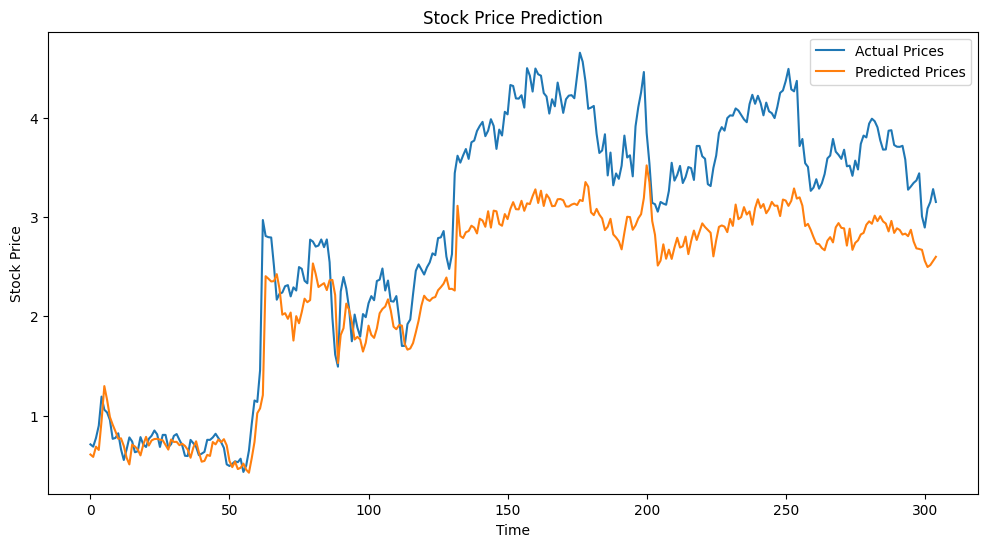

In [18]:
# Load the trained model
model = tf.keras.models.load_model('model.h5')

# Evaluate the model on the test set
X_test_reshaped = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))
test_loss = model.evaluate(X_test_reshaped, y_test, verbose=0)
print(f"Test Loss: {test_loss}")

# Make predictions on the test set
y_pred_scaled = model.predict(X_test_reshaped)

# Create a dummy array with 6 columns to inverse transform the predictions
dummy_pred = np.zeros((len(y_pred_scaled), 6))
dummy_pred[:, -1] = y_pred_scaled.flatten()
y_pred = scaler.inverse_transform(dummy_pred)[:, -1]

# Create a dummy array for the test set as well
dummy_test = np.zeros((len(y_test), 6))
dummy_test[:, -1] = y_test.flatten()
y_test_inversed = scaler.inverse_transform(dummy_test)[:, -1]


# Calculate and print evaluation metrics
mae = mean_absolute_error(y_test_inversed, y_pred)
mse = mean_squared_error(y_test_inversed, y_pred)
r2 = r2_score(y_test_inversed, y_pred)

print(f"Mean Absolute Error (MAE): {mae}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"R-squared (R2): {r2}")

# Plot the results
plt.figure(figsize=(12, 6))
plt.plot(y_test_inversed, label='Actual Prices')
plt.plot(y_pred, label='Predicted Prices')
plt.title('Stock Price Prediction')
plt.xlabel('Time')
plt.ylabel('Stock Price')
plt.legend()
plt.show()

In [35]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler
import ipywidgets as widgets
from IPython.display import display

# 1. Define your model architecture
def build_model(input_shape):
    model = Sequential()
    model.add(LSTM(units=100, return_sequences=True, input_shape=input_shape))
    model.add(Dropout(0.2))
    model.add(LSTM(units=50, return_sequences=False))
    model.add(Dropout(0.2))
    model.add(Dense(units=1))
    model.compile(optimizer='adam', loss='mean_squared_error')
    return model

# 2. Load your training data to fit the scaler
# Replace this with your actual training data loading code
# Example: df = pd.read_.csv('your_stock_data.csv')
training_data = X_train

# Initialize and fit the scaler with your training data
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(training_data)

# 3. Create prediction function
def predict_tomorrow_close(model, scaler, inputs):
    """
    inputs should be in order: Open, High, Low, Volume, Daily_Sentiment, Close
    """
    # Scale the inputs
    scaled_inputs = scaler.transform([inputs])

    # Reshape for LSTM (samples, timesteps, features)
    scaled_inputs = scaled_inputs.reshape((1, 6, 1))

    # Make prediction
    prediction = model.predict(scaled_inputs)

    # Inverse transform the prediction (assuming Close was the last feature)
    # This depends on how you scaled your target variable during training
    dummy = np.zeros((1, 6))
    dummy[0, -1] = prediction[0][0]  # Put prediction in Close position
    prediction = scaler.inverse_transform(dummy)[0, -1]

    return prediction

# 4. Create GUI widgets
open_input = widgets.FloatText(description='Open:')
high_input = widgets.FloatText(description='High:')
low_input = widgets.FloatText(description='Low:')
volume_input = widgets.FloatText(description='Volume:')
sentiment_input = widgets.FloatText(description='Sentiment:', value=0.0)
close_input = widgets.FloatText(description='Today Close:')

predict_button = widgets.Button(description="Predict Tomorrow's Close",
                              layout=widgets.Layout(width='200px'))
output_label = widgets.Label()

# 5. Create prediction handler
def on_predict_button_click(b):
    try:
        # Get all inputs
        inputs = [
            open_input.value,
            high_input.value,
            low_input.value,
            volume_input.value,
            sentiment_input.value,
            close_input.value
        ]

        # Make prediction (you need to load your trained model first)
        model = tf.keras.models.load_model('model.h5')
        prediction = predict_tomorrow_close(model, scaler, inputs)

        output_label.value = f"Predicted Tomorrow's Closing Price: {prediction:.2f}"
    except Exception as e:
        output_label.value = f"Error: {str(e)}"

predict_button.on_click(on_predict_button_click)

# 6. Display the GUI
input_box = widgets.VBox([
    widgets.Label("Enter Today's Market Data:"),
    open_input,
    high_input,
    low_input,
    volume_input,
    sentiment_input,
    close_input,
    widgets.HBox([predict_button]),
    output_label
], layout=widgets.Layout(width='500px'))

display(input_box)

# Note: Before using this, you need to:
# 1. Train your model (model.fit(...))
# 2. Fit your scaler with training data (scaler.fit(training_data))
# 3. Save your model (model.save('model.h5'))
# 4. In actual use, you would load the saved model instead of creating a new one

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 296ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 290ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 300ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step


... (5 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 300ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 303ms/step
